In [2]:
import os
import matplotlib.pyplot as plt
import numpy as np

folder_array = ['/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/2kpc',
          '/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/4kpc',
          '/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/6kpc',
          '/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/8kpc',
          '/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/10kpc',
          '/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/12kpc',
          '/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/14kpc',
          '/suphys/aani0116/Work/neutronstar_minicluster/hpc_run/20kpc']
f_distance_array=[]
m_init_distance_array=[]
mass_loss_distance=[]

folder=folder_array[-1]
files=os.listdir(folder)


In [3]:
for folder in folder_array:
    files = sorted(os.listdir(folder), key=lambda f: float(f.replace('mc_','').replace('.npz','')))
    m_mean=[]
    m_init=[]
    f_array=[]
    for f in files:
        d = np.load(os.path.join(folder, f))
        masses = d['masses']
        radiuses=d['radiuses']
        m_mean.append(masses[-1].mean())
        m_init.append(masses[0].mean())
        f_array.append((masses[-1] != 0).mean())   # survival fraction
    mass_loss_distance.append(np.array(m_mean)/np.array(m_init))
    f_distance_array.append(f_array)
    m_init_distance_array.append(m_init)


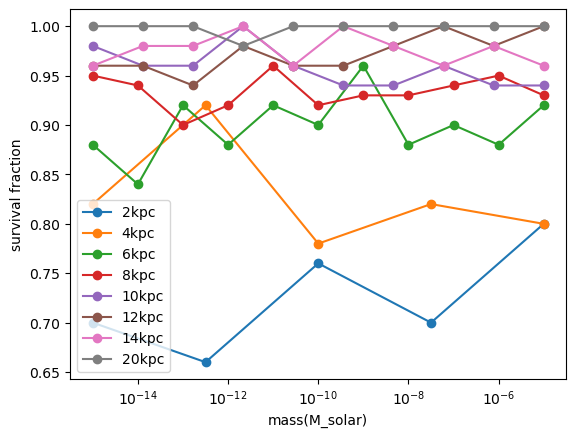

In [4]:
for folder, m_init, f_arr in zip(folder_array, m_init_distance_array, f_distance_array):
    plt.plot(m_init, f_arr, 'o-', label=os.path.basename(folder))
plt.ylabel('survival fraction')
plt.xlabel('mass(M_solar)')
plt.xscale('log')
plt.legend()


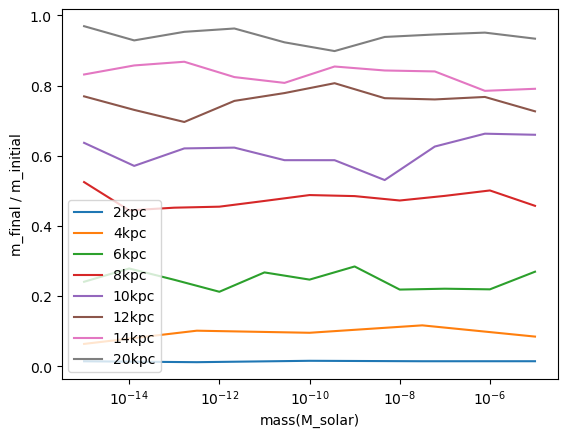

In [5]:
for folder, m_init, ml in zip(folder_array, m_init_distance_array, mass_loss_distance):
    plt.plot(m_init, ml, label=os.path.basename(folder))
plt.ylabel('m_final / m_initial')
plt.xlabel('mass(M_solar)')
plt.xscale('log')
plt.legend()



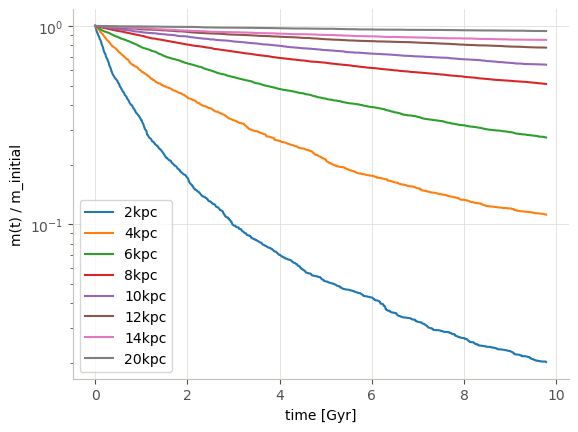

In [160]:
for folder in folder_array:
    files = sorted(os.listdir(folder), key=lambda f: float(f.replace('mc_','').replace('.npz','')))
    frac_t_all = []
    for f in files:
        masses = np.load(os.path.join(folder, f))['masses']
        alive = masses[-1] > 0
        frac_t_all.append(masses[:, alive] / masses[0, alive])   
    frac_t = np.hstack(frac_t_all)                                
    t_gyr = np.arange(len(frac_t)) * 0.01 * 0.978                 
    plt.plot(t_gyr, np.mean(frac_t, axis=1), label=os.path.basename(folder))
plt.ylabel('m(t) / m_initial')
plt.xlabel('time [Gyr]')
plt.yscale('log')
plt.legend()

In [ ]:
from scipy.interpolate import RegularGridInterpolator
import pandas as pd
df = pd.read_csv("/suphys/aani0116/Work/neutronstar_minicluster/output.dat", sep="\t")

NS_pos = df[['X (kpc)', 'Y (kpc)', 'Z (kpc)']].to_numpy()
x, y, z = NS_pos.T
R = np.hypot(x, y)

R_edges = np.arange(0, 30.01, 0.25)    # kpc
z_edges = np.arange(-3, 3.01, 0.05)    # kpc
counts, _, _ = np.histogram2d(R, z, bins=[R_edges, z_edges])

vol = np.pi * (R_edges[1:]**2 - R_edges[:-1]**2)[:, None] * np.diff(z_edges)[None, :]   
N_NS_MW = 1e9                                             
n_NS_grid = counts / vol * (N_NS_MW / len(NS_pos))        

R_mid = 0.5*(R_edges[1:] + R_edges[:-1])
z_mid = 0.5*(z_edges[1:] + z_edges[:-1])
_interp = RegularGridInterpolator((R_mid, z_mid), n_NS_grid, bounds_error=False, fill_value=0)

def n_NS(x, y, z):
    R = np.clip(np.hypot(x, y), R_mid[0], None)
    return _interp(np.column_stack([R, z]))


In [151]:
n_NS(8,0,0)

array([676755.83602201])

In [155]:
3.14*radiuses[-1]**2*n_NS(8,0,0)

array([2.65693681e-09, 2.65729334e-09, 2.74810570e-09, 2.65748729e-09,
       2.72742058e-09, 2.65862410e-09, 2.65056566e-09, 2.65691986e-09,
       2.66669541e-09, 7.14169079e-11, 2.66297174e-09, 1.74888547e-09,
       2.67939698e-09, 2.77455614e-09, 2.66231736e-09, 2.66548642e-09,
       2.65749901e-09, 2.65698450e-09, 2.68177947e-09, 1.11078341e-09,
       1.50041218e-09, 2.65778801e-09, 2.65880157e-09, 2.65759715e-09,
       2.65694685e-09, 2.65725243e-09, 2.65705877e-09, 2.66961435e-09,
       1.65772917e-09, 2.65695883e-09, 2.65691594e-09, 2.67158575e-09,
       8.26796573e-10, 2.65875316e-09, 2.65722370e-09, 2.65708344e-09,
       2.65697113e-09, 2.65871452e-09, 2.65870790e-09, 2.65697434e-09,
       2.68048510e-09, 2.13553031e-09, 2.65724418e-09, 2.67001485e-09,
       2.76914652e-09, 2.66133512e-09, 6.89919243e-10, 2.65856126e-09,
       2.98718982e-09, 2.79185302e-09])

In [1]:
pwd

'/suphys/aani0116/Work/neutronstar_minicluster/hpc_run'

In [ ]:
np.sqrt(np.random.uniform(0, (1e-3)**2, 10000000000))